<a href="https://colab.research.google.com/github/jha-rishika/Accident_Risk_KMeans/blob/Rishika_1289/Accident_Risk_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚦 Clustering Indian States, UTs & Cities by Traffic-Accident Severity (K-Means)

**Project type:** Unsupervised Machine Learning · **Algorithm:** K-Means · **Dataset:** `ADSI_Table_1A.2_2.csv` (Accidental Deaths & Suicides in India, Table 1A.2 – traffic accidents by State/UT/City)

**Goal:** Group individual States, Union Territories and major metropolitan cities into **accident-severity risk tiers** (High / Medium / Low) using only accident cases, injuries and deaths on roads, railways and railway crossings.

**Pipeline:** Load & clean → Select & scale features → Elbow method → Fit K-Means → Evaluate (Silhouette) → Visualize → Interpret.

> **How to run in Google Colab:** `Runtime → Run all`. When the upload prompt appears in Step 1, select `ADSI_Table_1A.2_2.csv`. (Alternatively, upload the file to the Colab file panel on the left before running.)

## Step 0 · Setup

**What this does:** imports the libraries (pandas/numpy for data, matplotlib/seaborn for plots, scikit-learn for scaling, K-Means and metrics) and fixes a random seed so results are reproducible.

**Key points**
- `RANDOM_STATE = 42` makes K-Means initialisation repeatable.
- No installs needed – Colab already ships with every library used here.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
CSV_PATH = "ADSI_Table_1A.2_2.csv"

## Step 1 · Data Loading & Preprocessing

### 1.1 Load the data
**What the code does:** reads the CSV with `encoding="latin1"` (the government file contains non-UTF-8 characters), uploads it through Colab if it is not already present, and **tags every row with an entity type** (State / UT / City). The raw file is ordered as *States → `Total (States)` → UTs → `Total (UTs)` → `Total (All India)` → Cities → `Total (Cities)`*, so we tag rows by position **before** removing the summary rows.

**Key points**
- `latin1` avoids `UnicodeDecodeError`.
- Entity type is a *label only* – it is **not** used as a clustering feature.

In [ ]:
# Upload helper: works in Colab; falls back silently when run locally.
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Please select ADSI_Table_1A.2_2.csv ...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{CSV_PATH} not found in the working directory.")

raw = pd.read_csv(CSV_PATH, encoding="latin1")
raw.columns = raw.columns.str.strip()
print("Raw shape:", raw.shape)

# Tag entity type by position in the file (before dropping the Total rows).
name_col = "State/UT/City"
names = raw[name_col].astype(str).str.strip()
entity, current = [], "State"
for n in names:
    entity.append(current)
    if n == "Total (States)":
        current = "UT"
    elif n == "Total (UTs)":
        current = "City"
raw["Entity Type"] = entity
raw.head()

Raw shape: (93, 14)


,Sl. No.,State/UT/City,Road Accidents - Cases,Road Accidents - Injured,Road Accidents - Died,Railway Accidents - Cases,Railway Accidents - Injured,Railway Accidents - Died,Railway Crossing Accidents - Cases,Railway Crossing Accidents - Injured,Railway Crossing Accidents - Died,Total Traffic Accidents - Cases,Total Traffic Accidents - Injured,Total Traffic Accidents - Died,Entity Type
0,1,Andhra Pradesh,21070,21340,8293,1029,0,1037,0,0,0,22099,21340,9330,State
1,2,Arunachal Pradesh,215,177,152,0,0,0,0,0,0,215,177,152,State
2,3,Assam,7028,5679,3060,689,0,693,22,0,22,7739,5679,3775,State
3,4,Bihar,10801,7068,8898,1444,6,1446,52,0,53,12297,7074,10397,State
4,5,Chhattisgarh,13091,11459,5890,429,21,429,4,0,4,13524,11480,6323,State


### 1.2 Remove summary (aggregate) rows
**What the code does:** drops every row whose name contains `"Total"` or `"All India"` (e.g. `Total (States)`, `Total (UTs)`, `Total (Cities)`, `Total (All India)`).

**Why this matters (theory):** K-Means is **centroid-based** – each centroid is the mean of its members. A summary row is the *sum* of dozens of entities, so it sits far from everything else. It would (a) become its own extreme "cluster", (b) drag centroids toward itself, (c) inflate the scale of every feature, and (d) **double-count** the same accidents that already appear in the individual rows. Only individual geographical entities should be clustered.

**Key points**
- Case-insensitive keyword match, so it is robust to spelling/case changes.
- We print which rows were removed as a sanity check.

In [ ]:
summary_mask = raw[name_col].astype(str).str.contains(r"total|all india", case=False, regex=True)
print("Summary rows removed:")
print(raw.loc[summary_mask, name_col].tolist())

df = raw.loc[~summary_mask].copy()
print("\nShape after removing summary rows:", df.shape)

Summary rows removed:
['Total (States)', 'Total (UTs)', 'Total (All India)', 'Total (Cities)']

Shape after removing summary rows: (89, 15)


### 1.3 Clean names, handle missing values and duplicates
**What the code does**
1. Trims whitespace and removes stray symbols (e.g. `Prayagraj +` → `Prayagraj`).
2. Converts all metric columns to numbers (`errors="coerce"` turns bad entries into `NaN`).
3. **Missing values:** drops rows with no name; fills remaining numeric gaps with the column **median** (robust to outliers).
4. **Duplicates:** removes repeated names, then removes rows whose *entire numeric profile is identical* to an earlier row. In this dataset `Chandigarh (city)` is numerically identical to the `Chandigarh` UT – keeping both would count the same place twice.

**Key points**
- Everything is done programmatically and every action is printed, so the cleaning is auditable.
- `Delhi (city)` differs slightly from the `Delhi` UT, so it is retained (a documented limitation: cities partially overlap their parent State/UT).

In [ ]:
metric_cols = [c for c in df.columns if c not in ["Sl. No.", name_col, "Entity Type"]]

# 1. Clean names
df[name_col] = (df[name_col].astype(str)
                .str.replace(r"[+*]", "", regex=True)
                .str.strip())

# 2. Numeric conversion
for c in metric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3. Missing values
print("Missing values before cleaning:\n", df[metric_cols + [name_col]].isna().sum()[lambda s: s > 0])
df = df.dropna(subset=[name_col])
df[metric_cols] = df[metric_cols].fillna(df[metric_cols].median())
print("Total missing values after cleaning:", int(df[metric_cols].isna().sum().sum()))

# 4. Duplicates
n0 = len(df)
df = df.drop_duplicates(subset=[name_col], keep="first")
dup_numeric = df.duplicated(subset=metric_cols, keep="first")
print("Rows with a numeric profile identical to an earlier row:", df.loc[dup_numeric, name_col].tolist())
df = df.loc[~dup_numeric].reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} after de-duplication")

print("\nEntities per type:\n", df["Entity Type"].value_counts())

Missing values before cleaning:
 Series([], dtype: int64)
Total missing values after cleaning: 0
Rows with a numeric profile identical to an earlier row: ['Chandigarh (city)']
Rows: 89 -> 88 after de-duplication

Entities per type:
 Entity Type
City     52
State    28
UT        8
Name: count, dtype: int64


**✅ Step 1 summary**
- Loaded with `latin1`; 4 aggregate rows removed so only real States/UTs/Cities remain.
- Names cleaned, numerics coerced, nulls median-imputed, duplicates dropped.
- Entity type kept as a label for later interpretation.

## Step 2 · Feature Selection & Feature Scaling

### 2.1 Select features
**What the code does:** selects the **9 base metrics** – *Cases, Injured, Died* for each of *Road, Railway, Railway Crossing* accidents.

**Why not the `Total Traffic Accidents` columns?** They are simply the sum of the road + railway + crossing columns. Including them would add perfectly redundant (collinear) information and silently give the same signal extra weight in the distance calculation. We keep them only for **plotting and interpretation**.

**Key points**
- 9 independent numeric features.
- `Total Traffic Accidents` columns are reserved for the scatter plot.

In [ ]:
feature_cols = [
    "Road Accidents - Cases", "Road Accidents - Injured", "Road Accidents - Died",
    "Railway Accidents - Cases", "Railway Accidents - Injured", "Railway Accidents - Died",
    "Railway Crossing Accidents - Cases", "Railway Crossing Accidents - Injured", "Railway Crossing Accidents - Died",
]
X = df[feature_cols].copy()
print("Feature matrix shape:", X.shape)
X.describe().T[["mean", "std", "min", "max"]]

Feature matrix shape: (88, 9)


,mean,std,min,max
Road Accidents - Cases,5828.772727,11896.291782,4.0,64105.0
Road Accidents - Injured,5455.625000,12075.606867,3.0,67703.0
Road Accidents - Died,2124.818182,4384.839757,2.0,24109.0
Railway Accidents - Cases,280.704545,731.294022,0.0,4827.0
Railway Accidents - Injured,29.113636,183.072653,0.0,1686.0
Railway Accidents - Died,252.659091,606.082197,0.0,3166.0
Railway Crossing Accidents - Cases,32.170455,156.651177,0.0,1340.0
Railway Crossing Accidents - Injured,1.284091,8.021449,0.0,54.0
Railway Crossing Accidents - Died,30.977273,154.773322,0.0,1340.0


### 2.2 Standardise with `StandardScaler`
**What the code does:** transforms every feature to **zero mean and unit variance**: $z = (x - \mu)/\sigma$.

**Why scaling is mandatory (theory):** K-Means assigns points using **Euclidean distance**, $d(x,c)=\sqrt{\sum_j (x_j-c_j)^2}$. Road-accident cases run into the tens of thousands while railway-crossing deaths are in the tens. Unscaled, the large-valued columns completely dominate the distance and the small ones are effectively ignored. Standardisation puts all features on a comparable scale so each contributes fairly.

**Key points**
- Fit the scaler on the feature matrix, then use the scaled matrix for all clustering steps.
- After scaling each column has mean ≈ 0 and std ≈ 1 (verified below).

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

check = pd.DataFrame(X_scaled, columns=feature_cols).agg(["mean", "std"]).T.round(3)
print(check)

                                      mean    std
Road Accidents - Cases                 0.0  1.006
Road Accidents - Injured              -0.0  1.006
Road Accidents - Died                 -0.0  1.006
Railway Accidents - Cases              0.0  1.006
Railway Accidents - Injured           -0.0  1.006
Railway Accidents - Died              -0.0  1.006
Railway Crossing Accidents - Cases    -0.0  1.006
Railway Crossing Accidents - Injured  -0.0  1.006
Railway Crossing Accidents - Died      0.0  1.006


**✅ Step 2 summary**
- 9 non-redundant features chosen; totals excluded from training.
- `StandardScaler` equalises feature influence on Euclidean distance.

## Step 3 · Finding the Optimal Number of Clusters (K)

**What the code does:** fits K-Means for every $K \in [1,10]$ and records the **WCSS / inertia**, then plots it. It also records the **Silhouette Score** for $K \ge 2$ as a second opinion.

**Theory – K-Means:** the algorithm (1) picks $K$ initial centroids (here `k-means++`), (2) assigns each point to its nearest centroid, (3) recomputes each centroid as the mean of its points, and (4) repeats 2–3 until assignments stop changing. It minimises

$$WCSS = \sum_{k=1}^{K}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2 .$$

**Theory – Elbow method:** WCSS always falls as $K$ grows (at $K=n$ it is 0). We look for the **"elbow"** – the $K$ after which extra clusters give diminishing returns. That point balances compact clusters against over-fragmentation.

**Theory – Silhouette (preview):** for each point, $s=\dfrac{b-a}{\max(a,b)}$, where $a$ is the mean distance to its own cluster and $b$ the mean distance to the nearest other cluster. Values near +1 mean compact, well-separated clusters.

**Key points**
- Lower WCSS = tighter clusters, but never choose $K$ on WCSS alone.
- Elbow + Silhouette together justify the final $K$.

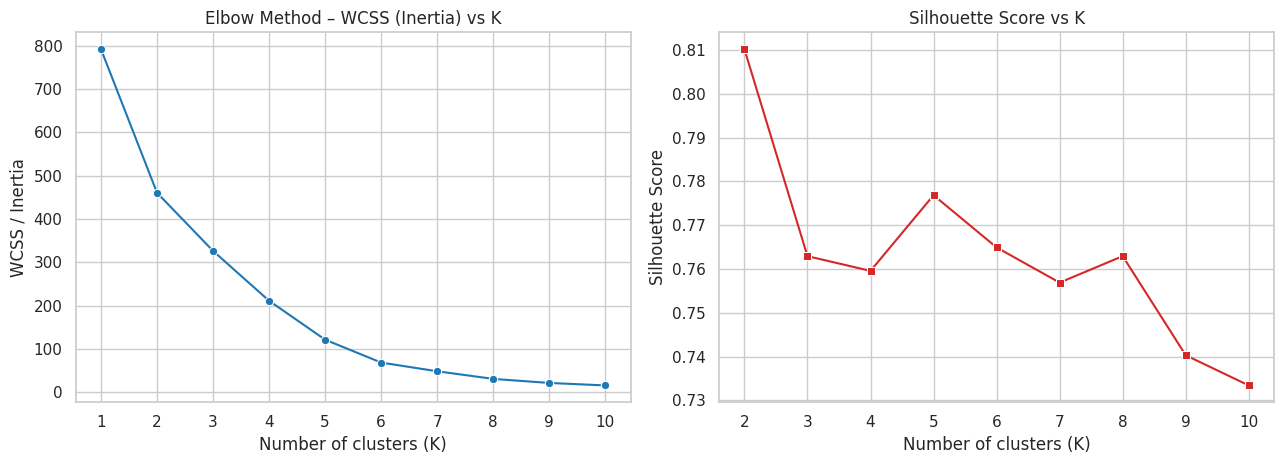

 K   WCSS  Silhouette
 1 792.00         NaN
 2 460.57      0.8102
 3 326.37      0.7629
 4 211.24      0.7596
 5 121.50      0.7769
 6  68.64      0.7649
 7  48.59      0.7569
 8  31.00      0.7629
 9  21.65      0.7403
10  15.90      0.7334


In [ ]:
K_RANGE = range(1, 11)
wcss, sil_scores = [], {}

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    if k >= 2:
        sil_scores[k] = silhouette_score(X_scaled, km.labels_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.lineplot(x=list(K_RANGE), y=wcss, marker="o", ax=axes[0], color="#1f77b4")
axes[0].set_title("Elbow Method – WCSS (Inertia) vs K")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("WCSS / Inertia")
axes[0].set_xticks(list(K_RANGE))

sns.lineplot(x=list(sil_scores.keys()), y=list(sil_scores.values()), marker="s", ax=axes[1], color="#d62728")
axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(sil_scores.keys()))

plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": list(K_RANGE), "WCSS": np.round(wcss, 2),
                    "Silhouette": [np.nan] + [round(sil_scores[k], 4) for k in range(2, 11)]}).to_string(index=False))

### Choosing K
Read the plots: the elbow is where the WCSS curve flattens, and the Silhouette curve shows which $K$ separates the data best. Because the project goal is **three risk tiers (High / Medium / Low)**, we use **K = 3** provided it sits at/near the elbow with a reasonable Silhouette score (checked in the next cell). Change `OPTIMAL_K` if you prefer another value.

**Key points**
- Elbow = diminishing returns; Silhouette = separation quality.
- K = 3 also maps naturally onto High / Medium / Low risk tiers.

In [ ]:
OPTIMAL_K = 3
print(f"Chosen K = {OPTIMAL_K} | WCSS = {wcss[OPTIMAL_K-1]:.1f} | Silhouette = {sil_scores[OPTIMAL_K]:.4f}")
print("Best Silhouette in K=2..10 is at K =", max(sil_scores, key=sil_scores.get))

Chosen K = 3 | WCSS = 326.4 | Silhouette = 0.7629
Best Silhouette in K=2..10 is at K = 2


**✅ Step 3 summary**
- WCSS plotted for K = 1…10; elbow identified visually.
- Silhouette curve used as a cross-check.
- Final choice: **K = 3** (High / Medium / Low).

## Step 4 · Model Implementation & Cluster Assignment

**What the code does:** fits the final `KMeans(n_clusters=3, init="k-means++", n_init=10)` on the scaled data and stores the raw cluster ids. Raw ids (0, 1, 2) are **arbitrary**, so we convert them to meaningful names: clusters are ranked by their **mean total deaths** – highest = **High Risk**, lowest = **Low Risk**.

**Key points**
- `n_init=10` runs 10 initialisations and keeps the best (lowest WCSS).
- Risk labels are derived from data (mean fatalities), not guessed.
- Labels are written back onto the cleaned dataframe.

In [ ]:
kmeans = KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=10, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Rank clusters by mean total deaths -> High / Medium / Low
order = df.groupby("Cluster")["Total Traffic Accidents - Died"].mean().sort_values(ascending=False).index.tolist()
tier_names = ["High Risk", "Medium Risk", "Low Risk"] if OPTIMAL_K == 3 else [f"Tier {i+1}" for i in range(OPTIMAL_K)]
label_map = dict(zip(order, tier_names))
df["Risk Tier"] = df["Cluster"].map(label_map)

print("Cluster -> Risk tier mapping:", label_map)
print(df["Risk Tier"].value_counts())
df[[name_col, "Entity Type", "Total Traffic Accidents - Cases", "Total Traffic Accidents - Died", "Risk Tier"]].head(10)

Cluster -> Risk tier mapping: {1: 'High Risk', 2: 'Medium Risk', 0: 'Low Risk'}
Risk Tier
Low Risk       76
Medium Risk    10
High Risk       2
Name: count, dtype: int64


,State/UT/City,Entity Type,Total Traffic Accidents - Cases,Total Traffic Accidents - Died,Risk Tier
0,Andhra Pradesh,State,22099,9330,Medium Risk
1,Arunachal Pradesh,State,215,152,Low Risk
2,Assam,State,7739,3775,Low Risk
3,Bihar,State,12297,10397,Medium Risk
4,Chhattisgarh,State,13524,6323,Low Risk
5,Goa,State,3066,328,Low Risk
6,Gujarat,State,16549,8417,Medium Risk
7,Haryana,State,11876,6424,Low Risk
8,Himachal Pradesh,State,2484,979,Low Risk
9,Jharkhand,State,5544,4251,Low Risk


**✅ Step 4 summary**
- K-Means fitted with k-means++ initialisation.
- Clusters ranked by mean fatalities and renamed High / Medium / Low Risk.

## Step 5 · Model Evaluation & Validation

**What the code does:** computes the **Silhouette Score** (and, as a bonus, the **Davies-Bouldin Index**) for the final model.

**How to read the metrics**
- **Silhouette** ranges from −1 to +1. Above ~0.5 = strong structure, 0.25–0.5 = reasonable, below 0.25 = weak/overlapping.
- **Davies-Bouldin** – *lower is better* (compact, well-separated clusters).
- **Inertia (WCSS)** measures compactness only; Silhouette also measures separation.

**Key points**
- Silhouette validates that clusters are both compact *and* far apart.
- Real-world accident data is heavily skewed (a few very large states), so moderate scores are expected.

In [ ]:
sil = silhouette_score(X_scaled, df["Cluster"])
dbi = davies_bouldin_score(X_scaled, df["Cluster"])

print(f"Silhouette Score     : {sil:.4f}")
print(f"Davies-Bouldin Index : {dbi:.4f}  (lower is better)")
print(f"Final WCSS (inertia) : {kmeans.inertia_:.2f}")

if sil >= 0.5:
    print("Interpretation: strong cluster structure.")
elif sil >= 0.25:
    print("Interpretation: reasonable cluster structure.")
else:
    print("Interpretation: weak/overlapping clusters.")

Silhouette Score     : 0.7629
Davies-Bouldin Index : 0.9173  (lower is better)
Final WCSS (inertia) : 326.37
Interpretation: strong cluster structure.


**✅ Step 5 summary**
- Silhouette Score printed and interpreted; Davies-Bouldin reported as a second check.

## Step 6 · Visualisations

### 6.1 Scatter plot – Total Accident Cases vs. Fatalities
**What the code does:** plots every entity by **Total Traffic Accident Cases (x)** vs **Total Deaths (y)**, colours points by risk tier and marks each **centroid** with a black ✕. Plot-axis centroids are the cluster means of those two variables (identical to the K-Means centroids projected onto those axes). The highest-fatality entities are annotated.

**Key points**
- Colour = risk tier, ✕ = centroid.
- Reveals how a handful of large states separate from the many smaller states and cities.

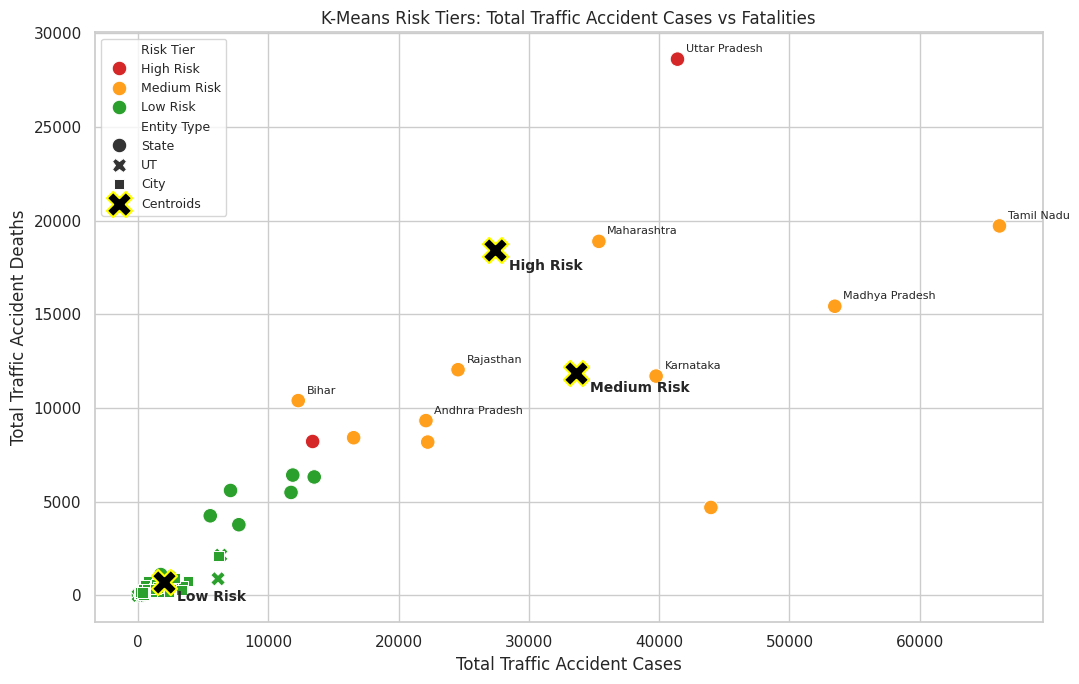

In [ ]:
palette = {"High Risk": "#d62728", "Medium Risk": "#ff9f1c", "Low Risk": "#2ca02c"}
xcol, ycol = "Total Traffic Accidents - Cases", "Total Traffic Accidents - Died"

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=df, x=xcol, y=ycol, hue="Risk Tier", palette=palette,
                hue_order=[t for t in tier_names if t in df["Risk Tier"].unique()],
                style="Entity Type", s=110, edgecolor="white", linewidth=0.7, ax=ax)

centroids = df.groupby("Risk Tier")[[xcol, ycol]].mean()
ax.scatter(centroids[xcol], centroids[ycol], marker="X", s=330, c="black",
           edgecolor="yellow", linewidth=1.5, label="Centroids", zorder=5)

for tier, row in centroids.iterrows():
    ax.annotate(tier, (row[xcol], row[ycol]), textcoords="offset points", xytext=(10, -14),
                fontsize=10, fontweight="bold")

for _, r in df.nlargest(8, ycol).iterrows():
    ax.annotate(r[name_col], (r[xcol], r[ycol]), textcoords="offset points", xytext=(6, 5), fontsize=8)

ax.set_title("K-Means Risk Tiers: Total Traffic Accident Cases vs Fatalities")
ax.set_xlabel("Total Traffic Accident Cases")
ax.set_ylabel("Total Traffic Accident Deaths")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

### 6.2 Cluster profiles & members
**What the code does:** summarises each tier (size and mean metrics), shows a composition table (State / UT / City per tier), and lists the members of each tier.

**Key points**
- Profiles turn abstract clusters into an interpretable risk narrative.
- Composition shows whether tiers are driven by states or by cities.

In [ ]:
profile = (df.groupby("Risk Tier")
             .agg(Entities=(name_col, "count"),
                  Avg_Cases=(xcol, "mean"),
                  Avg_Injured=("Total Traffic Accidents - Injured", "mean"),
                  Avg_Deaths=(ycol, "mean"))
             .round(0).reindex([t for t in tier_names if t in df["Risk Tier"].unique()]))
print(profile, "\n")
print(pd.crosstab(df["Risk Tier"], df["Entity Type"]), "\n")

for tier in profile.index:
    members = df.loc[df["Risk Tier"] == tier].sort_values(ycol, ascending=False)[name_col].tolist()
    print(f"{tier} ({len(members)}): {', '.join(members)}\n")

             Entities  Avg_Cases  Avg_Injured  Avg_Deaths
Risk Tier                                                
High Risk           2    27404.0      15099.0     18416.0
Medium Risk        10    33645.0      32821.0     11882.0
Low Risk           76     1963.0       1636.0       741.0 

Entity Type  City  State  UT
Risk Tier                   
High Risk       0      2   0
Low Risk       52     16   8
Medium Risk     0     10   0 

High Risk (2): Uttar Pradesh, West Bengal

Medium Risk (10): Tamil Nadu, Maharashtra, Madhya Pradesh, Rajasthan, Karnataka, Bihar, Andhra Pradesh, Gujarat, Telangana, Kerala

Low Risk (76): Haryana, Chhattisgarh, Punjab, Odisha, Jharkhand, Assam, Delhi, Delhi (city), Uttarakhand, Himachal Pradesh, Jaipur, Jammu and Kashmir, Kanpur, Bengaluru, Agra, Lucknow, Prayagraj, Mumbai, Ahmedabad, Chennai, Vijayawada, Ghaziabad, Nagpur, Asansol, Ludhiana, Pune, Vishakhapatnam, Surat, Goa, Hyderabad, Faridabad, Indore, Jodhpur, Coimbatore, Bhopal, Tripura, Nasik, Kol

**✅ Step 6 summary**
- Scatter plot shows tier separation with centroids marked.
- Profile tables convert clusters into actionable risk tiers.

## ⚠️ Limitations & Next Steps
- **Skewed data / outliers:** K-Means is sensitive to extreme values; a few very large states can form their own tiers.
- **Absolute counts, not rates:** larger populations and road networks naturally record more accidents. Normalising per 100,000 population or per km of road would measure *risk* more fairly.
- **Overlap:** cities lie inside States/UTs, so the same accidents partly appear twice across entities.
- **Next steps:** try per-capita features, `log1p` transforms, Hierarchical/DBSCAN clustering, and PCA for a 2-D projection of all 9 features.

# 🚦 Clustering Indian States, UTs & Cities by Traffic-Accident Severity (K-Means)

An unsupervised machine-learning project that groups Indian States, Union Territories and major metropolitan cities into **accident-severity risk tiers (High / Medium / Low)** using K-Means clustering on official government traffic-accident statistics.

## 📌 Project Objectives
- Clean the official ADSI traffic-accident table (`ADSI_Table_1A.2_2.csv`) so that only individual geographical entities are analysed.
- Scale features so Euclidean distances are meaningful across very different metric magnitudes.
- Find the number of clusters with the **Elbow Method** and cross-check with the **Silhouette Score**.
- Fit **K-Means**, label clusters as risk tiers, evaluate them and visualise the result.

## 🗂️ Dataset
| Item | Detail |
|---|---|
| File | `ADSI_Table_1A.2_2.csv` (encoding `latin1`) |
| Source | Accidental Deaths & Suicides in India (ADSI), Table 1A.2 – Traffic Accidents |
| Raw rows | 93 (incl. 4 summary rows: `Total (States)`, `Total (UTs)`, `Total (All India)`, `Total (Cities)`) |
| Rows after cleaning | **88** (28 States + 8 UTs + 52 Cities) |
| Features used | Cases, Injured, Died × {Road, Railway, Railway Crossing} = **9 features** |

## 🏗️ Architecture / Pipeline
```
CSV ──► Load (latin1) ──► Drop "Total"/"All India" rows ──► Clean names, nulls, duplicates
    ──► Select 9 features ──► StandardScaler ──► Elbow (K=1..10) + Silhouette
    ──► KMeans(K=3, k-means++) ──► Rank clusters by mean deaths → High / Medium / Low
    ──► Silhouette + Davies-Bouldin ──► Scatter plot with centroids + cluster profiles
```

### Key design decisions
- **Summary rows removed:** they are sums of many entities, so they would become extreme outliers, drag centroids and double-count accidents.
- **`StandardScaler`:** K-Means uses Euclidean distance; without scaling, large-valued columns (road cases) swamp small ones (crossing deaths).
- **Totals excluded from training:** `Total Traffic Accidents` = road + railway + crossing, so it is redundant; it is only used for plotting.
- **Duplicate handling:** `Chandigarh (city)` is numerically identical to the `Chandigarh` UT and is dropped.

## 👥 Team Role Breakdown
| Role | Responsibilities |
|---|---|
| **Data Preprocessing** | Load CSV, remove summary rows, clean names, handle nulls/duplicates, feature selection, scaling |
| **ML Modeling** | Elbow method, K selection, K-Means fitting, risk-tier labelling, Silhouette / Davies-Bouldin evaluation |
| **Documentation** | Markdown explanations, visualisations, README, presentation summary |

## ▶️ How to Run in Google Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → select `Accident_Risk_KMeans.ipynb`.
2. Click **Runtime → Run all**.
3. When prompted in Step 1, click **Choose files** and upload `ADSI_Table_1A.2_2.csv`
   (or upload it beforehand via the 📁 Files panel on the left).
4. Scroll through the outputs: elbow plot, Silhouette score, scatter plot, tier members.

> Runs locally too: `pip install pandas numpy matplotlib seaborn scikit-learn jupyter`.

## 📊 Key Results & Insights
| Metric | Value |
|---|---|
| Chosen K | **3** (High / Medium / Low) |
| Silhouette Score (K=3) | **≈ 0.76** (strong separation) |
| Highest Silhouette | K = 2 (≈ 0.81) |

| Risk tier | Members | Avg. total deaths |
|---|---|---|
| 🔴 **High Risk** (2) | Uttar Pradesh, West Bengal | ≈ 18,400 |
| 🟠 **Medium Risk** (10) | Tamil Nadu, Maharashtra, Madhya Pradesh, Rajasthan, Karnataka, Andhra Pradesh, Bihar, Gujarat, Telangana, Kerala | ≈ 11,900 |
| 🟢 **Low Risk** (76) | All other States, all UTs and all 52 cities | ≈ 740 |

**Insights**
- The data is **extremely skewed**: a dozen large states account for most accidents, so the Low-Risk tier is very large.
- **Uttar Pradesh and West Bengal form their own tier** mainly because of unusually high **railway and railway-crossing** accidents, not just road accidents.
- **Every city falls in the Low tier** because city-level counts are far smaller than state-level counts – cities and states should ideally be clustered separately.
- Silhouette is higher at K=2, but K=3 is kept to match the High/Medium/Low framework and still scores strongly.

## ⚠️ Limitations
- Absolute counts, not rates – large populations/road networks naturally record more accidents (use per-capita or per-km features next).
- Cities overlap with their parent State/UT.
- K-Means is outlier-sensitive; a `log1p` transform, DBSCAN or hierarchical clustering are good extensions.

## 🧰 Tech Stack
Python · pandas · NumPy · scikit-learn · matplotlib · seaborn · Google Colab

## 📁 Repository Structure
```
├── Accident_Risk_KMeans.ipynb
├── ADSI_Table_1A.2_2.csv
└── README.md
```

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving ADSI_Table_1A.2_2.csv to ADSI_Table_1A.2_2 (2).csv
